<a href="https://colab.research.google.com/github/krishnas2136/nba-player-stats-analysis/blob/main/NBA_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Libraries Load & Dataset Download

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset Kaggle se ya direct drive se load karein
# Link: https://www.kaggle.com/datasets/drgilermo/nba-players-stats
df = pd.read_csv('Seasons_Stats.csv')
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (10829, 53)


,Unnamed: 0,Year,Player,Pos,Age,Tm,G,GS,MP,PER,...,FT%,ORB,DRB,TRB,AST,STL,BLK,TOV,PF,PTS
0,0,1950.0,Curly Armstrong,G-F,31.0,FTW,63.0,NaN,NaN,NaN,...,0.705,NaN,NaN,NaN,176.0,NaN,NaN,NaN,217.0,458.0
1,1,1950.0,Cliff Barker,SG,29.0,INO,49.0,NaN,NaN,NaN,...,0.708,NaN,NaN,NaN,109.0,NaN,NaN,NaN,99.0,279.0
2,2,1950.0,Leo Barnhorst,SF,25.0,CHS,67.0,NaN,NaN,NaN,...,0.698,NaN,NaN,NaN,140.0,NaN,NaN,NaN,192.0,438.0
3,3,1950.0,Ed Bartels,F,24.0,TOT,15.0,NaN,NaN,NaN,...,0.559,NaN,NaN,NaN,20.0,NaN,NaN,NaN,29.0,63.0
4,4,1950.0,Ed Bartels,F,24.0,DNN,13.0,NaN,NaN,NaN,...,0.548,NaN,NaN,NaN,20.0,NaN,NaN,NaN,27.0,59.0


In [ ]:
print("Dataset Info:")
print(df.info())
print("\nDataset Description:")
print(df.describe())
print("\nDataset Columns:")
print(df.columns)
print("\nDataset Data Types:")
print(df.dtypes)
print("\nDataset Null Values:")
print(df.isnull().sum())
print(df.shape)

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
Index: 9033 entries, 32 to 10723
Data columns (total 52 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Year    9033 non-null   int64  
 1   Player  9033 non-null   object 
 2   Pos     9033 non-null   object 
 3   Age     9033 non-null   int64  
 4   Tm      9033 non-null   object 
 5   G       9033 non-null   float64
 6   GS      3702 non-null   float64
 7   MP      8674 non-null   float64
 8   PER     8643 non-null   float64
 9   TS%     9020 non-null   float64
 10  3PAr    4258 non-null   float64
 11  FTr     9016 non-null   float64
 12  ORB%    5819 non-null   float64
 13  DRB%    5819 non-null   float64
 14  TRB%    6466 non-null   float64
 15  AST%    7304 non-null   float64
 16  STL%    5819 non-null   float64
 17  BLK%    5819 non-null   float64
 18  TOV%    4823 non-null   float64
 19  USG%    4830 non-null   float64
 20  blanl   0 non-null      float64
 21  OWS     8994 non-null   fl

Data Cleaning (Missing Values, Duplicates, Data Types)

In [ ]:
# 1. Unnecessary columns drop karein
if 'Unnamed: 0' in df.columns:
    df.drop(columns=['Unnamed: 0'], inplace=True)
    print("Dropped Unnamed: 0 Column")

# 2. Missing percentage & numerical stats ko 0 se fill karein
pct_cols = ['FG%', '3P%', '2P%', 'eFG%', 'FT%']
df[pct_cols] = df[pct_cols].fillna(0)
print("Filled Missing Percentage Values with 0")

num_cols = ['PTS', 'AST', 'TRB', 'STL', 'BLK', 'TOV']
df[num_cols] = df[num_cols].fillna(0)
print("Filled Missing Numerical Values with 0")

# 3. Critical rows se missing values hatayein
df.dropna(subset=['Player', 'Year', 'Pos'], inplace=True)
print("Dropped Rows with Missing Values in 'Player', 'Year', or 'Pos'")

# 4. Duplicate player rows (agar player season ke beech team badla ho) remove karein
df = df.sort_values(by=['Year', 'Player', 'G'], ascending=[True, True, False])
df = df.drop_duplicates(subset=['Year', 'Player'], keep='first')
print("Dropped Duplicate Player Rows")

# 5. Data Types correct karein
df['Year'] = df['Year'].astype(int)
df['Age'] = df['Age'].fillna(df['Age'].median()).astype(int)


print("Cleaned Data Shape:", df.shape)

Filled Missing Percentage Values with 0
Filled Missing Numerical Values with 0
Dropped Rows with Missing Values in 'Player', 'Year', or 'Pos'
Dropped Duplicate Player Rows
Cleaned Data Shape: (9033, 52)


Visualization 1 - Top 10 Scorers (Bar Chart)

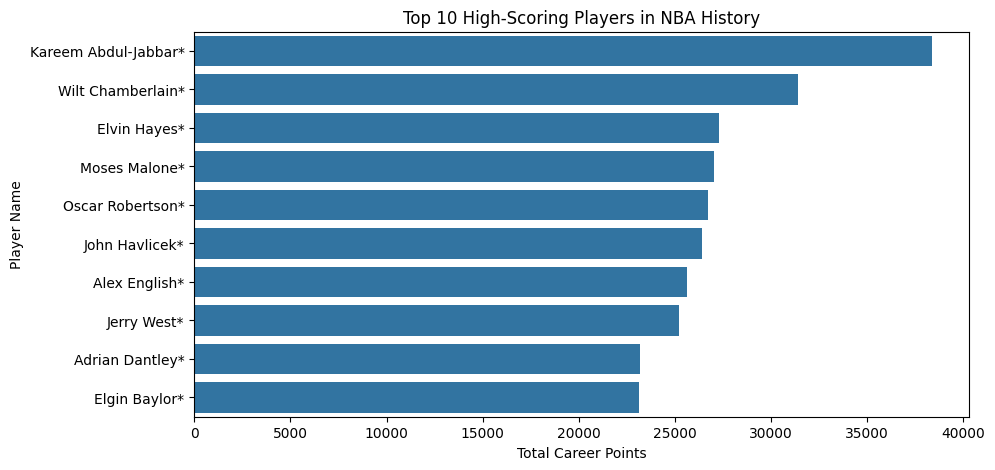

In [ ]:
top_scorers = df.groupby('Player')['PTS'].sum().nlargest(10).reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=top_scorers, x='PTS', y='Player')
plt.title('Top 10 High-Scoring Players in NBA History')
plt.xlabel('Total Career Points')
plt.ylabel('Player Name')
plt.show()

Visualization 2 - Age vs. Points (Scatter Plot)

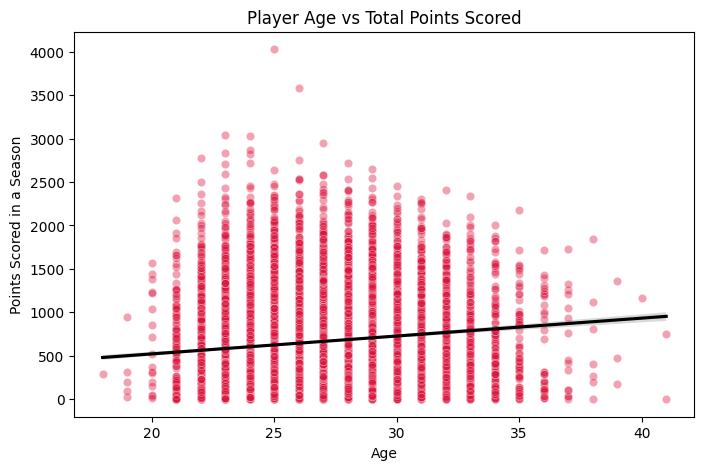

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Age', y='PTS', alpha=0.4, color='crimson')
sns.regplot(data=df, x='Age', y='PTS', scatter=False, color='black')
plt.title('Player Age vs Total Points Scored')
plt.xlabel('Age')
plt.ylabel('Points Scored in a Season')
plt.show()

Visualization 3 - Points by Position (Box Plot)

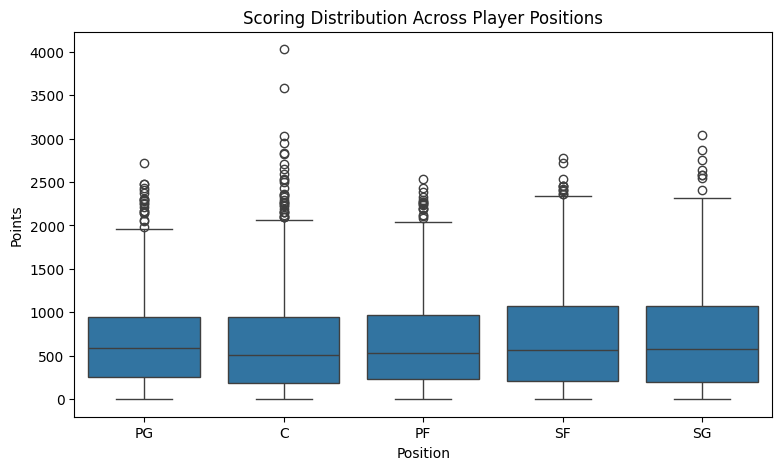

In [ ]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df[df['Pos'].isin(['PG', 'SG', 'SF', 'PF', 'C'])], x='Pos', y='PTS')
plt.title('Scoring Distribution Across Player Positions')
plt.xlabel('Position')
plt.ylabel('Points')
plt.show()

Visualization 4 - Decade Scoring Trend (Line Chart)

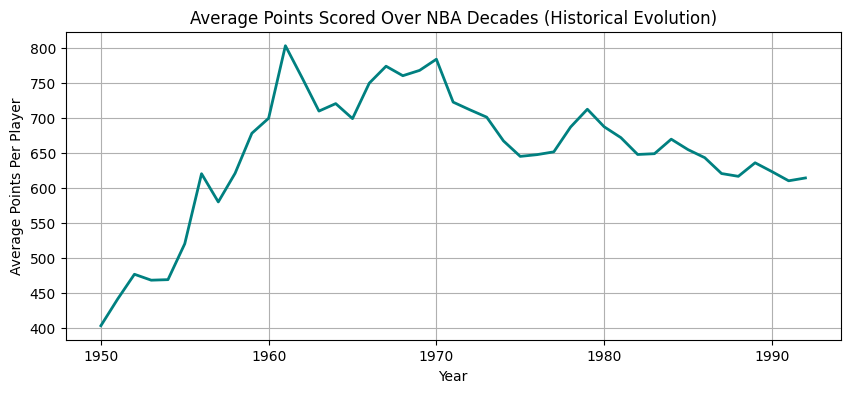

In [ ]:
decade_avg = df.groupby('Year')['PTS'].mean().reset_index()

plt.figure(figsize=(10, 4))
sns.lineplot(data=decade_avg, x='Year', y='PTS', color='teal', linewidth=2)
plt.title('Average Points Scored Over NBA Decades (Historical Evolution)')
plt.xlabel('Year')
plt.ylabel('Average Points Per Player')
plt.grid(True)
plt.show()

Visualization 5 - Correlation Heatmap

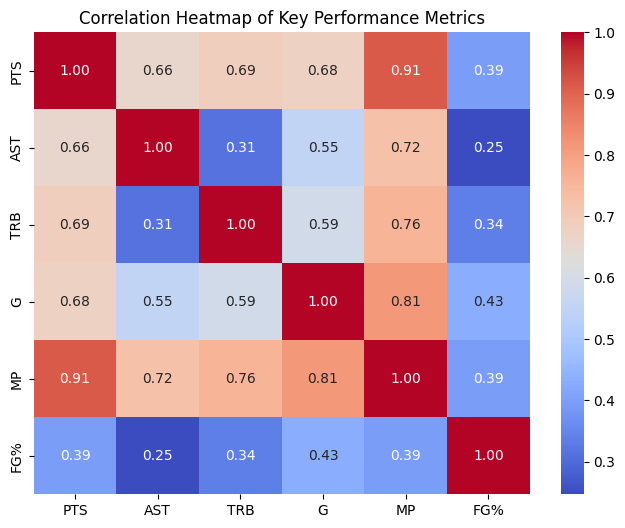

In [ ]:
plt.figure(figsize=(8, 6))
corr = df[['PTS', 'AST', 'TRB', 'G', 'MP', 'FG%']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Key Performance Metrics')
plt.show()

Visualization 6 - Field Goal % Distribution (Histogram)

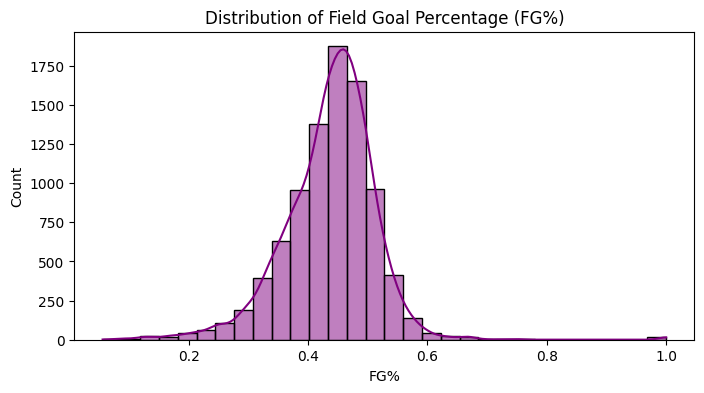

In [ ]:
plt.figure(figsize=(8, 4))
sns.histplot(df[df['FG%'] > 0]['FG%'], kde=True, color='purple', bins=30)
plt.title('Distribution of Field Goal Percentage (FG%)')
plt.xlabel('FG%')
plt.ylabel('Count')
plt.show()

1.Peak Performance Age: NBA players hit their maximum scoring capacity between ages 24 and 28.

2.Positional Insights: Small Forwards (SF) and Shooting Guards (SG) show higher upper ranges in points compared to Centers (C).

3.Historical Shift: Game scoring sharply increased post-1980s due to faster game pace and introduction of the 3-point line.

4.Minutes Played Correlation: Playing time (MP) shows the strongest positive correlation with total points (PTS).